In [55]:
import pandas as pd
import time
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    classification_report
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [56]:
import pandas as pd

df = pd.read_csv("../data/sms_spam.csv")

print("Columns:", df.columns.tolist())
print("Dataset shape:", df.shape)

print("\nClass distribution:")
print(df["label"].value_counts())

display(df.head())

Columns: ['text', 'label']
Dataset shape: (5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


,text,label
0,"Go until jurong point, crazy.. Available only ...",ham
1,Ok lar... Joking wif u oni...,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,spam
3,U dun say so early hor... U c already then say...,ham
4,"Nah I don't think he goes to usf, he lives aro...",ham


In [57]:
# Separate input text and target labels
X = df["text"]
y = df["label"]

print("Total messages:", len(X))
print("Total labels:", len(y))

Total messages: 5572
Total labels: 5572


In [58]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
# The same test set will be used in every experiment.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 4457
Test samples: 1115


In [59]:
# Deliberately restrict the amount of real training data
# We retain only 20% of the original training set.

X_real, _, y_real, _ = train_test_split(
    X_train,
    y_train,
    train_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Limited real training samples:", len(X_real))

print("\nClass distribution of limited real data:")
print(y_real.value_counts())

Limited real training samples: 891

Class distribution of limited real data:
label
ham     771
spam    120
Name: count, dtype: int64


In [60]:
print("Limited real training set:")
print(y_real.value_counts())

print("\nTotal:", len(y_real))

Limited real training set:
label
ham     771
spam    120
Name: count, dtype: int64

Total: 891


In [61]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

def create_model():
    return Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                stop_words="english",
                ngram_range=(1, 2)
            )
        ),
        (
            "classifier",
            LogisticRegression(max_iter=1000)
        )
    ])

model = create_model()

print("Model created successfully.")

Model created successfully.


In [62]:
import time

# Create a fresh model for the baseline experiment
baseline_model = create_model()

# Start training timer
start_time = time.time()

# Train using limited real data only
baseline_model.fit(X_real, y_real)

# Stop timer
training_time = time.time() - start_time

print(f"Training completed in {training_time:.4f} seconds.")

Training completed in 0.0345 seconds.


In [63]:
# Make predictions on the fixed real test set
y_pred = baseline_model.predict(X_test)

print("Prediction completed.")

Prediction completed.


In [64]:
from sklearn.metrics import accuracy_score, f1_score, matthews_corrcoef

accuracy = accuracy_score(y_test, y_pred)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

mcc = matthews_corrcoef(
    y_test,
    y_pred
)

print("REAL DATA ONLY")
print("==========================")
print(f"Accuracy   : {accuracy:.4f}")
print(f"Macro-F1   : {macro_f1:.4f}")
print(f"MCC        : {mcc:.4f}")
print(f"Train Time : {training_time:.4f} seconds")

REAL DATA ONLY
Accuracy   : 0.8744
Macro-F1   : 0.5232
MCC        : 0.2297
Train Time : 0.0345 seconds


In [65]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         ham       0.87      1.00      0.93       966
        spam       1.00      0.06      0.11       149

    accuracy                           0.87      1115
   macro avg       0.94      0.53      0.52      1115
weighted avg       0.89      0.87      0.82      1115



## Synthetic Data Generation

Synthetic labelled SMS examples were generated using a generative AI system
(ChatGPT) for the HAM and SPAM classes.

The synthetic dataset contains 891 examples:
- 771 HAM messages
- 120 SPAM messages

The synthetic data is used only for training. The original real test set
remains unchanged across all experiments.

In [66]:
# Load the synthetic dataset
synthetic_df = pd.read_csv("../data/synthetic_data.csv")

# Clean column names
synthetic_df.columns = synthetic_df.columns.str.strip().str.lower()

print("Synthetic dataset shape:", synthetic_df.shape)

print("\nSynthetic class distribution:")
print(synthetic_df["label"].value_counts())

print("\nFirst 5 synthetic messages:")
display(synthetic_df.head())

Synthetic dataset shape: (891, 2)

Synthetic class distribution:
label
ham     771
spam    120
Name: count, dtype: int64

First 5 synthetic messages:


,text,label
0,Can you remind me about tomorrow’s appointment...,ham
1,Did anyone take notes during the guest lecture?,ham
2,You are eligible for a complimentary health an...,spam
3,The package was delivered to the reception desk.,ham
4,What chapter did you cover in class?,ham


In [67]:
# Basic validation

assert list(synthetic_df.columns) == ["text", "label"], \
    "Synthetic dataset must contain 'text' and 'label' columns."

assert len(synthetic_df) == 891, \
    f"Expected 891 synthetic messages, found {len(synthetic_df)}."

assert synthetic_df["text"].notna().all(), \
    "Synthetic dataset contains missing text values."

assert synthetic_df["label"].isin(["ham", "spam"]).all(), \
    "Labels must only be 'ham' or 'spam'."

assert synthetic_df["text"].is_unique, \
    "Synthetic dataset contains duplicate messages."

print("Synthetic dataset validation passed!")

Synthetic dataset validation passed!


In [68]:
# Create nested synthetic subsets.
# This means:
# 25% subset is contained within the 50% subset,
# and the 50% subset is contained within the 100% subset.

ham_synthetic = (
    synthetic_df[synthetic_df["label"] == "ham"]
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

spam_synthetic = (
    synthetic_df[synthetic_df["label"] == "spam"]
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

# Required numbers
ham_25 = 193
spam_25 = 30

ham_50 = 386
spam_50 = 60

ham_100 = 771
spam_100 = 120

# Create subsets
synthetic_25 = pd.concat([
    ham_synthetic.iloc[:ham_25],
    spam_synthetic.iloc[:spam_25]
], ignore_index=True)

synthetic_50 = pd.concat([
    ham_synthetic.iloc[:ham_50],
    spam_synthetic.iloc[:spam_50]
], ignore_index=True)

synthetic_100 = pd.concat([
    ham_synthetic.iloc[:ham_100],
    spam_synthetic.iloc[:spam_100]
], ignore_index=True)

print("Synthetic 25%:", len(synthetic_25))
print(synthetic_25["label"].value_counts())

print("\nSynthetic 50%:", len(synthetic_50))
print(synthetic_50["label"].value_counts())

print("\nSynthetic 100%:", len(synthetic_100))
print(synthetic_100["label"].value_counts())

Synthetic 25%: 223
label
ham     193
spam     30
Name: count, dtype: int64

Synthetic 50%: 446
label
ham     386
spam     60
Name: count, dtype: int64

Synthetic 100%: 891
label
ham     771
spam    120
Name: count, dtype: int64


In [69]:
def run_experiment(experiment_name, X_train_exp, y_train_exp):
    """
    Train and evaluate one experiment.

    The model is always trained using the same
    TF-IDF + Logistic Regression pipeline and
    evaluated on the same real test set.
    """

    model = create_model()

    start_time = time.perf_counter()

    model.fit(X_train_exp, y_train_exp)

    training_time = time.perf_counter() - start_time

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro")
    mcc = matthews_corrcoef(y_test, predictions)

    return {
        "Experiment": experiment_name,
        "Real Samples": len(X_real),
        "Synthetic Samples": len(X_train_exp) - len(X_real),
        "Total Training Samples": len(X_train_exp),
        "Accuracy": accuracy,
        "Macro-F1": macro_f1,
        "MCC": mcc,
        "Training Time (sec)": training_time
    }

In [70]:
# -----------------------------
# EXPERIMENT 1: REAL ONLY
# -----------------------------
X_exp_real = X_real.reset_index(drop=True)
y_exp_real = y_real.reset_index(drop=True)

result_real = run_experiment(
    "Real Only",
    X_exp_real,
    y_exp_real
)


# -----------------------------
# EXPERIMENT 2: REAL + 25%
# -----------------------------
X_exp_25 = pd.concat([
    X_real.reset_index(drop=True),
    synthetic_25["text"]
], ignore_index=True)

y_exp_25 = pd.concat([
    y_real.reset_index(drop=True),
    synthetic_25["label"]
], ignore_index=True)

result_25 = run_experiment(
    "Real + 25% Synthetic",
    X_exp_25,
    y_exp_25
)


# -----------------------------
# EXPERIMENT 3: REAL + 50%
# -----------------------------
X_exp_50 = pd.concat([
    X_real.reset_index(drop=True),
    synthetic_50["text"]
], ignore_index=True)

y_exp_50 = pd.concat([
    y_real.reset_index(drop=True),
    synthetic_50["label"]
], ignore_index=True)

result_50 = run_experiment(
    "Real + 50% Synthetic",
    X_exp_50,
    y_exp_50
)


# -----------------------------
# EXPERIMENT 4: REAL + 100%
# -----------------------------
X_exp_100 = pd.concat([
    X_real.reset_index(drop=True),
    synthetic_100["text"]
], ignore_index=True)

y_exp_100 = pd.concat([
    y_real.reset_index(drop=True),
    synthetic_100["label"]
], ignore_index=True)

result_100 = run_experiment(
    "Real + 100% Synthetic",
    X_exp_100,
    y_exp_100
)


# Combine all results
results_df = pd.DataFrame([
    result_real,
    result_25,
    result_50,
    result_100
])

results_df

,Experiment,Real Samples,Synthetic Samples,Total Training Samples,Accuracy,Macro-F1,MCC,Training Time (sec)
0,Real Only,891,0,891,0.874439,0.523178,0.229688,0.040721
1,Real + 25% Synthetic,891,223,1114,0.881614,0.570433,0.316824,0.033320
2,Real + 50% Synthetic,891,446,1337,0.888789,0.613523,0.385613,0.051787
3,Real + 100% Synthetic,891,891,1782,0.893274,0.638588,0.423391,0.062246


In [71]:
# Create results folder if it doesn't exist
from pathlib import Path

results_folder = Path("../results")
figures_folder = results_folder / "figures"

results_folder.mkdir(exist_ok=True)
figures_folder.mkdir(exist_ok=True)

# Save complete results
results_df.to_csv(
    results_folder / "results.csv",
    index=False
)

print("Saved:")
print(results_folder / "results.csv")

Saved:
..\results\results.csv


In [72]:
comparison_table = results_df[
    [
        "Experiment",
        "Accuracy",
        "Macro-F1",
        "MCC",
        "Training Time (sec)"
    ]
].copy()

comparison_table = comparison_table.round(4)

display(comparison_table)

comparison_table.to_csv(
    results_folder / "comparison_table.csv",
    index=False
)

print("Comparison table saved.")

,Experiment,Accuracy,Macro-F1,MCC,Training Time (sec)
0,Real Only,0.8744,0.5232,0.2297,0.0407
1,Real + 25% Synthetic,0.8816,0.5704,0.3168,0.0333
2,Real + 50% Synthetic,0.8888,0.6135,0.3856,0.0518
3,Real + 100% Synthetic,0.8933,0.6386,0.4234,0.0622


Comparison table saved.


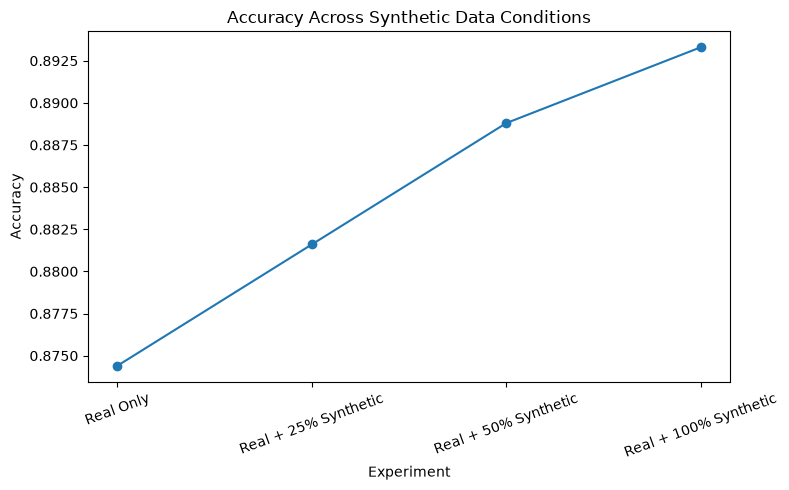

In [73]:
plt.figure(figsize=(8, 5))

plt.plot(
    comparison_table["Experiment"],
    comparison_table["Accuracy"],
    marker="o"
)

plt.xlabel("Experiment")
plt.ylabel("Accuracy")
plt.title("Accuracy Across Synthetic Data Conditions")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    figures_folder / "accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

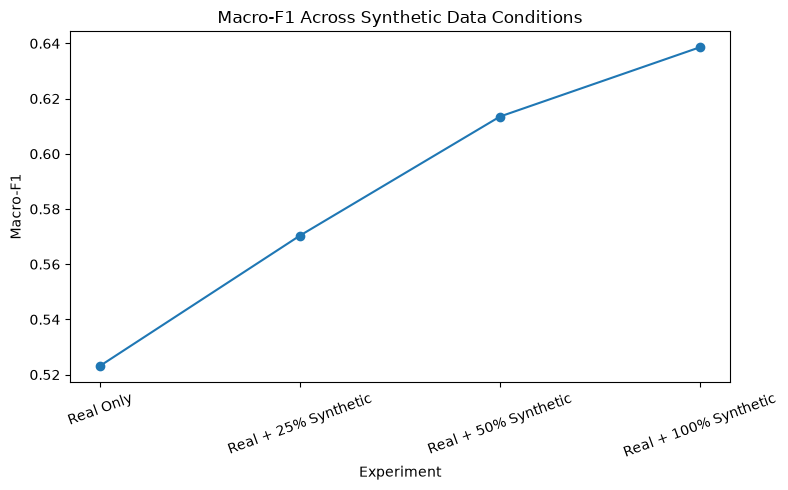

In [74]:
plt.figure(figsize=(8, 5))

plt.plot(
    comparison_table["Experiment"],
    comparison_table["Macro-F1"],
    marker="o"
)

plt.xlabel("Experiment")
plt.ylabel("Macro-F1")
plt.title("Macro-F1 Across Synthetic Data Conditions")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    figures_folder / "macro_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

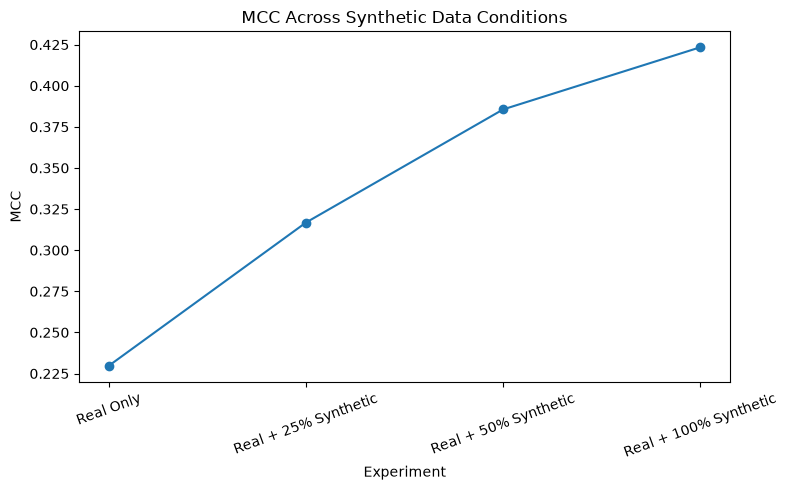

In [75]:
plt.figure(figsize=(8, 5))

plt.plot(
    comparison_table["Experiment"],
    comparison_table["MCC"],
    marker="o"
)

plt.xlabel("Experiment")
plt.ylabel("MCC")
plt.title("MCC Across Synthetic Data Conditions")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    figures_folder / "mcc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

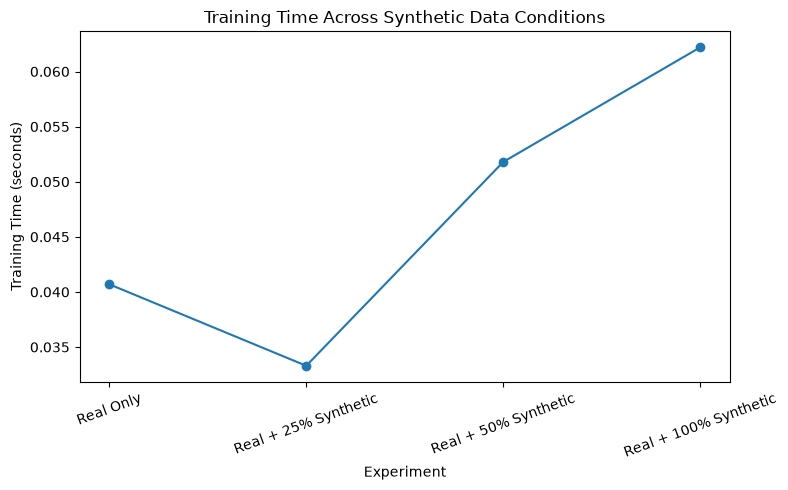

In [76]:
plt.figure(figsize=(8, 5))

plt.plot(
    comparison_table["Experiment"],
    comparison_table["Training Time (sec)"],
    marker="o"
)

plt.xlabel("Experiment")
plt.ylabel("Training Time (seconds)")
plt.title("Training Time Across Synthetic Data Conditions")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    figures_folder / "training_time_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()